# Stress Testing de un portafolio correlacionado

Se construye un portafolio balanceado con cinco acciones de sectores distintos, se simula su valor a un año con correlación (Cholesky) y se somete a tres escenarios de estrés.

| Activo | Empresa | Sector |
|---|---|---|
| AMD | Advanced Micro Devices | Semiconductores |
| DAL | Delta Air Lines | Aerolíneas |
| COST | Costco | Consumo básico |
| NU | Nu Holdings | Fintech |
| CVX | Chevron | Energía |

**Inversión inicial:** $V_0 = 100{,}000$ USD, con 20,000 USD en cada activo.

**Escenarios de estrés:**

| Escenario | Choque | ¿Se vuelve a simular? |
|---|---|---|
| 1. Caída de precios | Cada $S_T$ baja 35% | No |
| 2. Volatilidad | $\sigma_i \times 2$ | Sí |
| 3. Correlación | $\rho_{ij} = 1$ | Sí |

---

### Librerías

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

---

# Parte 1. Datos y parámetros

### Descarga de precios de los últimos 3 años

In [2]:
tickers = ["AMD", "DAL", "COST", "NU", "CVX"]

data = yf.download(tickers, start="2023-11-18", end="2026-11-18",
                   auto_adjust=True, progress=False)

precios = data["Close"][tickers].dropna()
print(f"Observaciones: {len(precios)}")
precios.tail()

Observaciones: 751


Ticker,AMD,DAL,COST,NU,CVX
Date,,,,,
2026-11-11,552.900024,91.320000,1087.609985,12.32,211.523468
2026-11-12,585.299988,86.550003,1092.209961,11.83,214.568192
2026-11-13,534.059998,86.250000,1106.209961,13.22,218.079025
2026-11-16,504.279999,86.599998,1113.739990,12.68,215.351669
2026-11-17,503.410004,84.300003,1110.079956,12.33,214.350006


### Evolución de los precios (base 100)

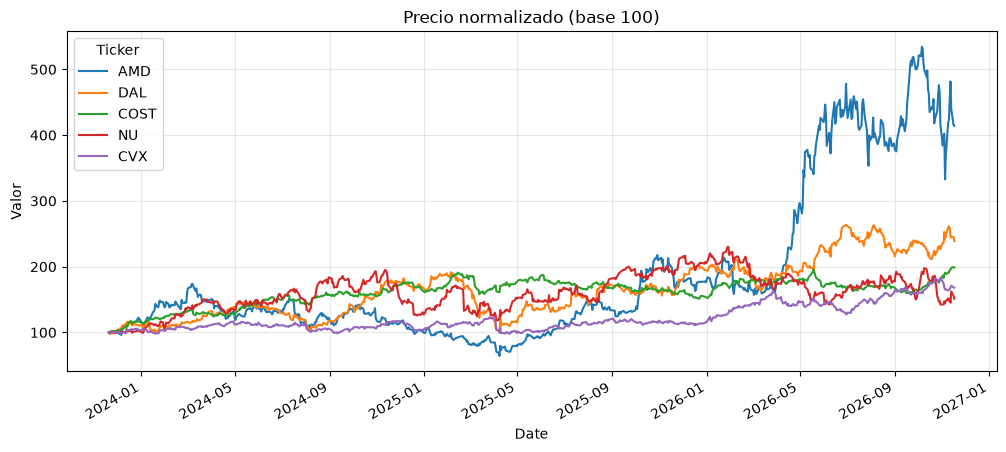

In [3]:
(precios / precios.iloc[0] * 100).plot(figsize=(12, 5), lw=1.5)
plt.title("Precio normalizado (base 100)")
plt.ylabel("Valor")
plt.grid(alpha=0.3)
plt.show()

### Rendimientos, volatilidad y tendencia de cada activo

- $\sigma_i$ y $\Sigma$ se estiman con los 3 años de datos.
- La tendencia $r_i$ es el rendimiento logarítmico anual del último año (252 días hábiles).

In [4]:
log_ret = np.log(precios / precios.shift(1)).dropna()

correlacion = log_ret.corr()
covarianza  = log_ret.cov() * 252
sigma = np.sqrt(np.diag(covarianza))

r  = log_ret.iloc[-252:].mean() * 252
S0 = precios.iloc[-1]

pd.DataFrame({"S0": S0, "r (último año)": r, "sigma": sigma}).round(4)

,S0,r (último año),sigma
Ticker,,,
AMD,503.41,0.7128,0.6087
DAL,84.30,0.3775,0.4093
COST,1110.08,0.1905,0.2054
NU,12.33,-0.2492,0.4450
CVX,214.35,0.3543,0.2294


### Matriz de correlación histórica

In [5]:
correlacion.round(3)

Ticker,AMD,DAL,COST,NU,CVX
Ticker,,,,,
AMD,1.000,0.347,0.021,0.293,0.027
DAL,0.347,1.000,0.160,0.316,0.055
COST,0.021,0.160,1.000,0.150,0.082
NU,0.293,0.316,0.150,1.000,0.068
CVX,0.027,0.055,0.082,0.068,1.000


### Portafolio balanceado

Cada activo recibe el 20% de la inversión, así que se compran $N_i = \dfrac{0.2 \cdot V_0}{S_i(0)}$ acciones (en fracciones, para que el balance sea exacto).

In [6]:
V0 = 100_000
w  = np.full(len(tickers), 1 / len(tickers))
N  = w * V0 / S0.values

pd.DataFrame({"Peso": w, "Inversión (USD)": w * V0, "Acciones": N},
             index=tickers).round(4)

,Peso,Inversión (USD),Acciones
AMD,0.2,20000.0,39.7290
DAL,0.2,20000.0,237.2479
COST,0.2,20000.0,18.0167
NU,0.2,20000.0,1622.0600
CVX,0.2,20000.0,93.3053


---

# Parte 2. Simulación base

$$S_i(T) = S_i(0)\, e^{\left(r_i - \frac{1}{2}\Sigma_{ii}\right)T + \sqrt{T}\, Z_i}, \qquad Z = L\,\varepsilon$$

Los mismos $\varepsilon$ se usan en todos los escenarios, para que las diferencias se deban solo al choque aplicado.

### Choques independientes ε ~ N(0, I)

In [7]:
M = 10_000
T = 1

np.random.seed(42)
epsilon = np.random.normal(0, 1, [M, len(tickers)])

### Funciones de apoyo

- `simular_precios`: recibe la matriz $L$ y la matriz $\Sigma$ de un escenario y regresa los precios a un año.
- `metricas`: calcula el valor final promedio, la mediana, la desviación, la probabilidad de pérdida, el VaR y el CVaR al 5%.

In [8]:
def simular_precios(L, Sigma):
    Z = epsilon @ L.T
    drift = (r.values - 0.5 * np.diag(Sigma)) * T
    ST = S0.values * np.exp(drift + np.sqrt(T) * Z)
    return pd.DataFrame(ST, columns=tickers)


def metricas(VT):
    PnL = VT - V0
    p5  = PnL.quantile(0.05)
    return {
        "V_T promedio": VT.mean(),
        "V_T mediana": VT.median(),
        "Desv. est.": VT.std(),
        "P(pérdida) (%)": (PnL < 0).mean() * 100,
        "VaR 5%": -p5,
        "CVaR 5%": -PnL[PnL <= p5].mean(),
    }

### Cholesky y precios del escenario base

In [9]:
Sigma_base = covarianza.values
L_base = np.linalg.cholesky(Sigma_base)

ST_base = simular_precios(L_base, Sigma_base)

pd.DataFrame({"S0": S0,
              "Media S_T simulada": ST_base.mean(),
              "E[S_T] teórico": S0.values * np.exp(r.values * T)}).round(2)

,S0,Media S_T simulada,E[S_T] teórico
AMD,503.41,1031.11,1026.79
DAL,84.30,123.71,122.97
COST,1110.08,1340.91,1342.98
NU,12.33,9.60,9.61
CVX,214.35,305.23,305.50


### Valor final del escenario base

$$V_T = \sum_i N_i \, S_i(T)$$

In [10]:
VT_base = pd.Series(ST_base.values @ N, name="Base")

pd.Series(metricas(VT_base)).round(2)

V_T promedio      138523.20
V_T mediana       131593.59
Desv. est.         38840.41
P(pérdida) (%)        12.00
VaR 5%             10078.17
CVaR 5%            17095.00
dtype: float64

---

# Parte 3. Stress Testing

## Escenario 1. Cada precio final baja 35%

Se toma cada precio simulado del escenario base y se multiplica por 0.65:

$$S_i^{\text{estrés}}(T) = 0.65 \cdot S_i(T)$$

No hace falta volver a simular: el choque se aplica sobre los mismos escenarios. Como todos los activos bajan en la misma proporción, el valor del portafolio también baja exactamente 35% en cada escenario.

In [11]:
ST_s1 = ST_base * (1 - 0.35)
VT_s1 = pd.Series(ST_s1.values @ N, name="Caída 35%")

pd.Series(metricas(VT_s1)).round(2)

V_T promedio      90040.08
V_T mediana       85535.83
Desv. est.        25246.27
P(pérdida) (%)       72.63
VaR 5%            41550.81
CVaR 5%           46111.75
dtype: float64

## Escenario 2. La volatilidad se duplica

Si cada $\sigma_i$ se multiplica por 2, la covarianza entre dos activos se multiplica por 4, porque $\text{Cov}_{ij} = \rho_{ij}\,\sigma_i\,\sigma_j$:

$$\Sigma^{\text{estrés}} = (2\sigma_i)(2\sigma_j)\,\rho_{ij} = 4\,\Sigma$$

La correlación no cambia. El ajuste $-\frac{1}{2}\Sigma_{ii}$ se recalcula con la nueva varianza, así que el precio **esperado** sigue creciendo a la tasa $r_i$, pero la distribución se vuelve mucho más ancha.

In [12]:
Sigma_s2 = covarianza.values * 4
L_s2 = np.linalg.cholesky(Sigma_s2)

pd.DataFrame({"sigma base": sigma,
              "sigma estresada": np.sqrt(np.diag(Sigma_s2))}, index=tickers).round(4)

,sigma base,sigma estresada
AMD,0.6087,1.2175
DAL,0.4093,0.8186
COST,0.2054,0.4107
NU,0.4450,0.8900
CVX,0.2294,0.4589


In [13]:
ST_s2 = simular_precios(L_s2, Sigma_s2)
VT_s2 = pd.Series(ST_s2.values @ N, name="Volatilidad x2")

pd.Series(metricas(VT_s2)).round(2)

V_T promedio      138972.80
V_T mediana       115764.49
Desv. est.         97577.71
P(pérdida) (%)        37.67
VaR 5%             40712.84
CVaR 5%            48155.59
dtype: float64

## Escenario 3. Correlación perfecta (ρ = 1)

Con $\rho_{ij} = 1$ todos los activos se mueven exactamente igual. La matriz de correlación es una matriz de puros unos, y la covarianza queda:

$$\Sigma^{\text{estrés}}_{ij} = \sigma_i\,\sigma_j$$

### Problema: Cholesky no funciona

Cholesky solo existe para matrices **definidas positivas**, es decir, con todos sus eigenvalores mayores que cero. Una matriz de unos de $5 \times 5$ tiene eigenvalores $5, 0, 0, 0, 0$: solo hay **una** dirección de variación, porque todos los activos son el mismo movimiento con distinta escala.

In [14]:
correlacion_s3 = np.ones((len(tickers), len(tickers)))
Sigma_s3 = np.outer(sigma, sigma) * correlacion_s3

print("Eigenvalores de la matriz de correlación:")
print(np.linalg.eigvalsh(correlacion_s3).round(6))

try:
    np.linalg.cholesky(Sigma_s3)
    print("\nCholesky funcionó")
except np.linalg.LinAlgError as error:
    print(f"\nCholesky falla: {error}")

Eigenvalores de la matriz de correlación:
[-0. -0.  0.  0.  5.]

Cholesky falla: Matrix is not positive definite


### Solución: un solo choque para todos los activos

Si todos los activos se mueven igual, basta **un solo** número aleatorio por escenario. Cada activo lo recibe escalado por su propia volatilidad:

$$Z_i = \sigma_i \, \varepsilon_1$$

En forma matricial, $L$ es una matriz cuya primera columna son las volatilidades y el resto son ceros. Sigue cumpliendo $L\,L^T = \Sigma$, así que se puede usar con la misma función de simulación.

In [15]:
L_s3 = np.zeros((len(tickers), len(tickers)))
L_s3[:, 0] = sigma

print(f"¿L · Lᵀ reconstruye Σ? {np.allclose(L_s3 @ L_s3.T, Sigma_s3)}")
pd.DataFrame(L_s3, index=tickers, columns=tickers).round(4)

¿L · Lᵀ reconstruye Σ? True


,AMD,DAL,COST,NU,CVX
AMD,0.6087,0.0,0.0,0.0,0.0
DAL,0.4093,0.0,0.0,0.0,0.0
COST,0.2054,0.0,0.0,0.0,0.0
NU,0.4450,0.0,0.0,0.0,0.0
CVX,0.2294,0.0,0.0,0.0,0.0


In [16]:
ST_s3 = simular_precios(L_s3, Sigma_s3)
VT_s3 = pd.Series(ST_s3.values @ N, name="Correlación = 1")

print("Correlación simulada de los rendimientos:")
print(np.log(ST_s3 / S0.values).corr().round(3))

pd.Series(metricas(VT_s3)).round(2)

Correlación simulada de los rendimientos:
      AMD  DAL  COST   NU  CVX
AMD   1.0  1.0   1.0  1.0  1.0
DAL   1.0  1.0   1.0  1.0  1.0
COST  1.0  1.0   1.0  1.0  1.0
NU    1.0  1.0   1.0  1.0  1.0
CVX   1.0  1.0   1.0  1.0  1.0


V_T promedio      138560.52
V_T mediana       126931.73
Desv. est.         59020.20
P(pérdida) (%)        27.42
VaR 5%             31832.26
CVaR 5%            40645.97
dtype: float64

---

# Parte 4. Comparación de escenarios

### Tabla comparativa

In [17]:
escenarios = {
    "Base": VT_base,
    "Caída 35%": VT_s1,
    "Volatilidad x2": VT_s2,
    "Correlación = 1": VT_s3,
}

tabla = pd.DataFrame({nombre: metricas(VT) for nombre, VT in escenarios.items()}).T
tabla.round(2)

,V_T promedio,V_T mediana,Desv. est.,P(pérdida) (%),VaR 5%,CVaR 5%
Base,138523.20,131593.59,38840.41,12.00,10078.17,17095.00
Caída 35%,90040.08,85535.83,25246.27,72.63,41550.81,46111.75
Volatilidad x2,138972.80,115764.49,97577.71,37.67,40712.84,48155.59
Correlación = 1,138560.52,126931.73,59020.20,27.42,31832.26,40645.97


### Histogramas de pérdidas y ganancias de cada escenario

Las barras rojas son el 5% de peores escenarios. La línea negra marca el punto de equilibrio, la dorada la media, la naranja el VaR y la morada el CVaR.

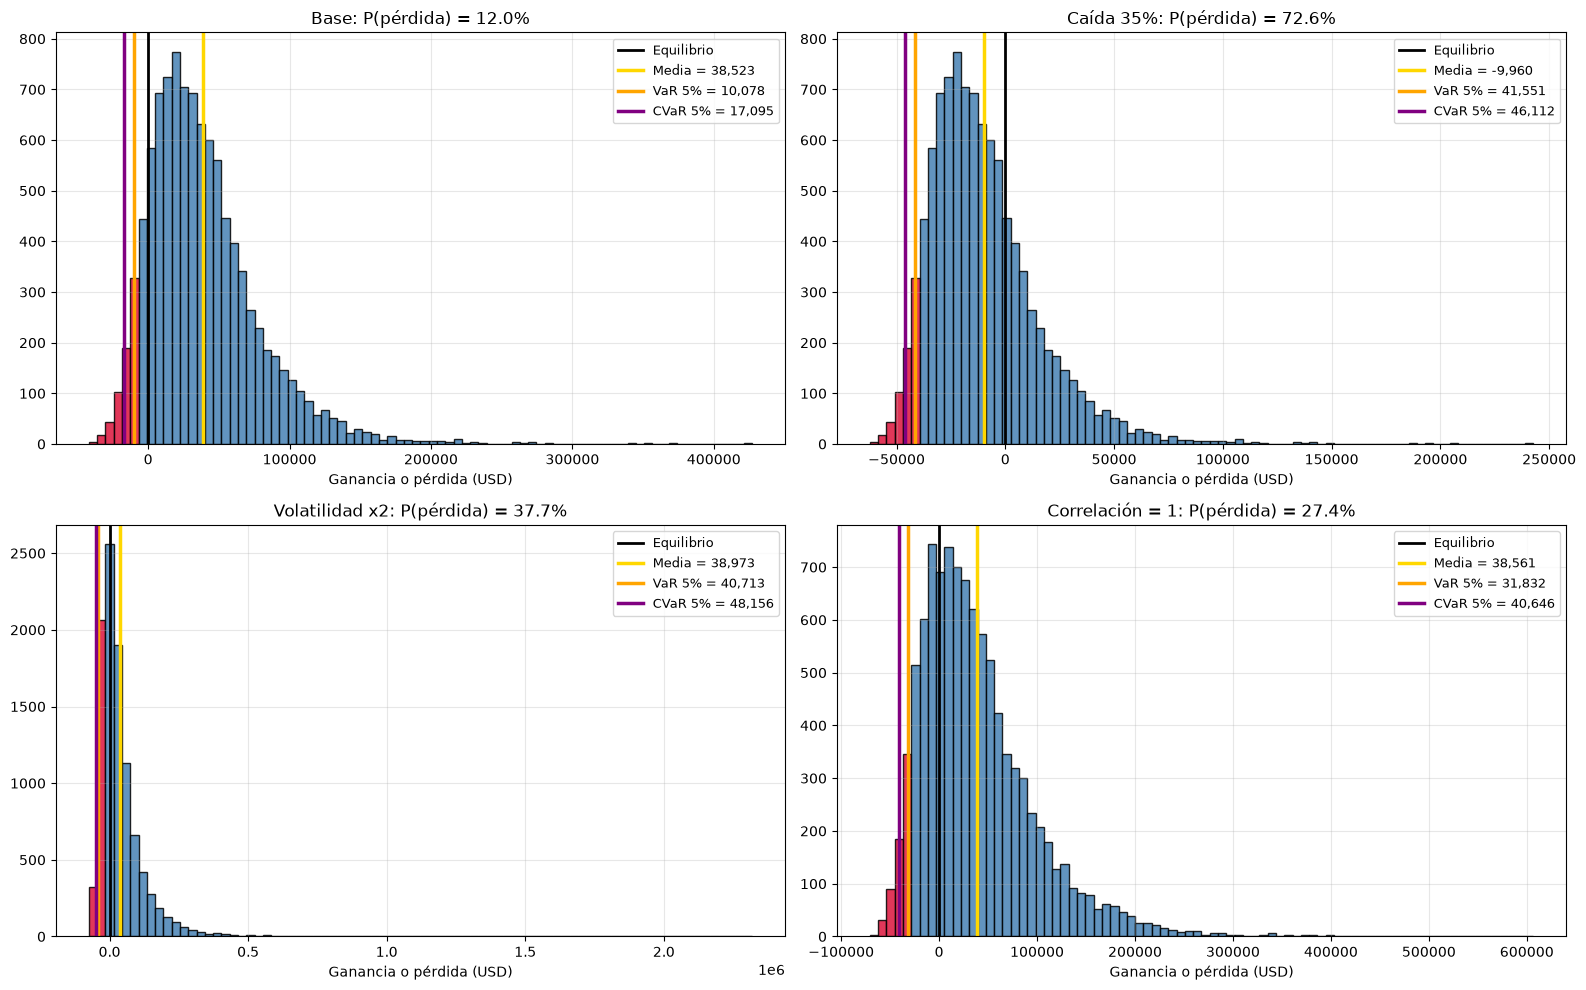

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, (nombre, VT) in zip(axes.flat, escenarios.items()):
    PnL  = VT - V0
    p5   = PnL.quantile(0.05)
    cvar = PnL[PnL <= p5].mean()

    n_barras, bins, barras = ax.hist(PnL, bins=80, color="steelblue",
                                     edgecolor="black", alpha=0.85)
    for barra, borde_izq in zip(barras, bins[:-1]):
        if borde_izq < p5:
            barra.set_facecolor("crimson")

    ax.axvline(0, color="black", lw=2, label="Equilibrio")
    ax.axvline(PnL.mean(), color="gold", lw=2.5, label=f"Media = {PnL.mean():,.0f}")
    ax.axvline(p5,   color="orange", lw=2.5, label=f"VaR 5% = {-p5:,.0f}")
    ax.axvline(cvar, color="purple", lw=2.5, label=f"CVaR 5% = {-cvar:,.0f}")

    ax.set_title(f"{nombre}: P(pérdida) = {(PnL < 0).mean()*100:.1f}%")
    ax.set_xlabel("Ganancia o pérdida (USD)")
    ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Escenario base vs cada escenario de estrés

Cada panel compara la distribución de pérdidas y ganancias del escenario base (gris) con la de un escenario de estrés. Las líneas punteadas marcan el VaR 5% de cada uno; la distancia entre ellas es lo que el choque aumenta la pérdida en el 5% de peores escenarios.

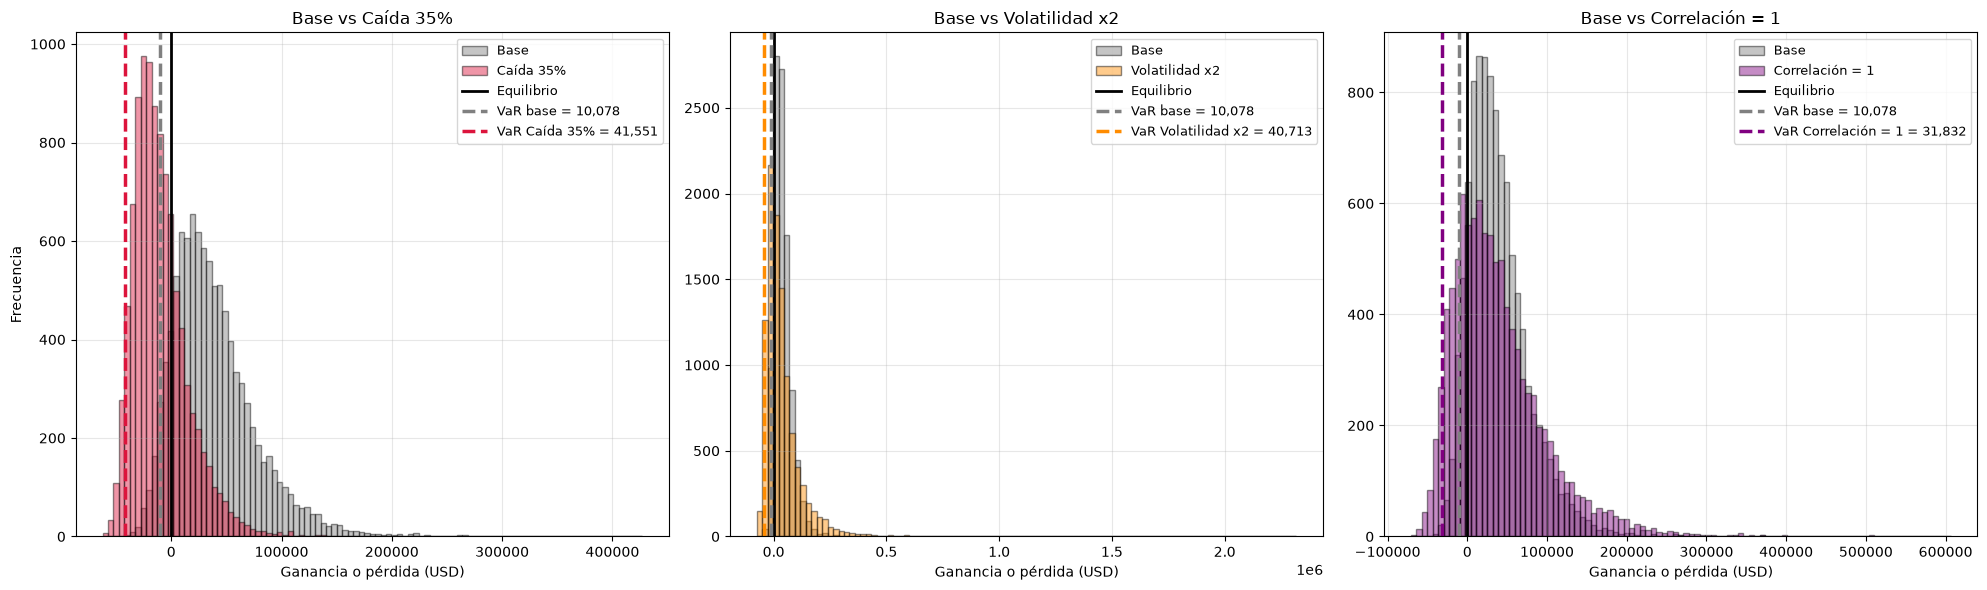

In [19]:
estres = {
    "Caída 35%": (VT_s1, "crimson"),
    "Volatilidad x2": (VT_s2, "darkorange"),
    "Correlación = 1": (VT_s3, "purple"),
}

PnL_base = VT_base - V0
var_base = -PnL_base.quantile(0.05)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, (nombre, (VT, color)) in zip(axes, estres.items()):
    PnL_estres = VT - V0
    var_estres = -PnL_estres.quantile(0.05)

    bins = np.linspace(min(PnL_base.min(), PnL_estres.min()),
                       max(PnL_base.max(), PnL_estres.max()), 100)

    ax.hist(PnL_base, bins=bins, alpha=0.45, color="gray", edgecolor="black",
            label="Base")
    ax.hist(PnL_estres, bins=bins, alpha=0.45, color=color, edgecolor="black",
            label=nombre)

    ax.axvline(0, color="black", lw=2, label="Equilibrio")
    ax.axvline(-var_base, color="gray", ls="--", lw=2.5,
               label=f"VaR base = {var_base:,.0f}")
    ax.axvline(-var_estres, color=color, ls="--", lw=2.5,
               label=f"VaR {nombre} = {var_estres:,.0f}")

    ax.set_title(f"Base vs {nombre}")
    ax.set_xlabel("Ganancia o pérdida (USD)")
    ax.legend(fontsize=9); ax.grid(alpha=0.3)

axes[0].set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()